# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import pandas as pd
import seaborn as sns

# Cargar los datos
data = sns.load_dataset('titanic')

# LabelEncoder para sex
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

# OneHotEncoder para sex
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
sex_encoded = onehot_encoder.fit_transform(data[['sex']])

sex_onehot = pd.DataFrame(
    sex_encoded,
    columns=onehot_encoder.get_feature_names_out(['sex']),
    index=data.index
)

# Mostrar la comparación
print("LabelEncoder:")
print(data[['sex', 'sex_label']].head())

print("\nOneHotEncoder:")
print(sex_onehot.head())


LabelEncoder:
      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1

OneHotEncoder:
   sex_female  sex_male
0         0.0       1.0
1         1.0       0.0
2         1.0       0.0
3         1.0       0.0
4         0.0       1.0


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

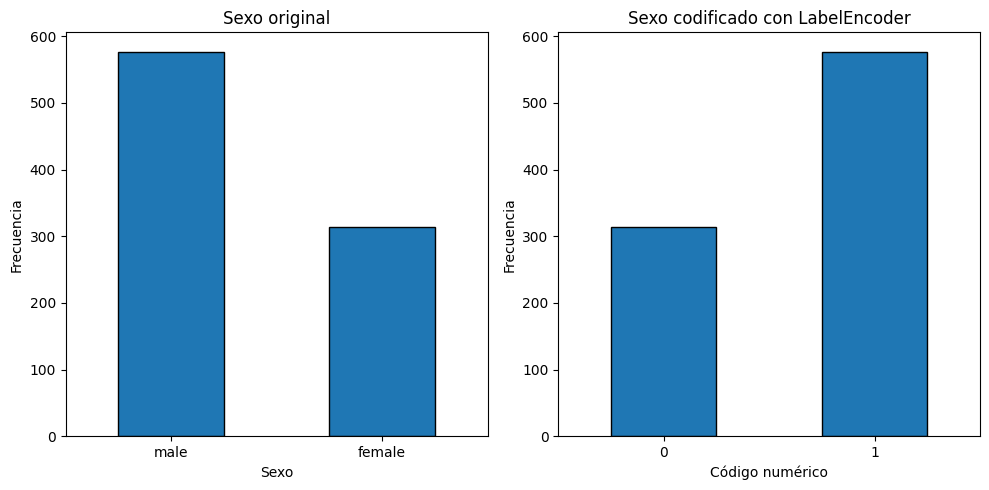

Mapeo de categorías:
female = 0
male = 1


In [9]:

import matplotlib.pyplot as plt

# Frecuencias originales
frecuencias_originales = data['sex'].value_counts()

# Frecuencias después de LabelEncoder
frecuencias_codificadas = data['sex_label'].value_counts().sort_index()

# Crear gráficas
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

frecuencias_originales.plot(
    kind='bar', ax=axes[0], edgecolor='black'
)
axes[0].set_title('Sexo original')
axes[0].set_xlabel('Sexo')
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=0)

frecuencias_codificadas.plot(
    kind='bar', ax=axes[1], edgecolor='black'
)
axes[1].set_title('Sexo codificado con LabelEncoder')
axes[1].set_xlabel('Código numérico')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Mostrar qué categoría corresponde a cada número
print("Mapeo de categorías:")
for codigo, categoria in enumerate(label_encoder.classes_):
    print(f"{categoria} = {codigo}")


### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:

# Crear y ajustar el codificador
onehot_class = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

# Codificar la columna class
class_encoded = onehot_class.fit_transform(data[['class']])

# Crear un DataFrame con las nuevas columnas
class_df = pd.DataFrame(
    class_encoded,
    columns=onehot_class.get_feature_names_out(['class']),
    index=data.index
)

# Combinar con los datos originales
data = pd.concat([data, class_df], axis=1)

# Mostrar resultados
print(data[['class'] + list(class_df.columns)].head())


   class  class_First  class_Second  class_Third
0  Third          0.0           0.0          1.0
1  First          1.0           0.0          0.0
2  Third          0.0           0.0          1.0
3  First          1.0           0.0          0.0
4  Third          0.0           0.0          1.0


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

##### El tipo de código que elegiría seria OneHotEncoder porque no existe un orden natural entre sus categorías 